# 03 · Candidate-budget curves, with exact dataset versions
**Primary study:** fixed Learned weights, 160 fitting updates at each K, no fallback.
Six models × three datasets × three seeds = 54 cells. K = 1,2,4,8,16,80.
Electricity: 321 channels, L512/H96; National Illness: 7 channels, L104/H24;
Exchange Rate: 8 channels, L512/H96. National Illness has only eight test origins.


In [1]:
from pathlib import Path
import sys, json
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'artifacts/manifest.json').exists())
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from ttc4ts.results import (checked_path, load_snapshot, geometric, summarize,
    main_summary, lw_budget_summary, uncertainty_summary, MODELS, MODEL_LABELS, METHODS, METHOD_LABELS)
%matplotlib inline
plt.rcParams.update({'figure.dpi': 115, 'font.family': 'DejaVu Sans', 'font.size': 10,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .18})
pd.set_option('display.max_rows', 60)
pd.set_option('display.float_format', lambda x: f'{x:.5f}')
print('Offline mode: numerical snapshots are verified against the released SHA-256 manifest.')


Offline mode: numerical snapshots are verified against the released SHA-256 manifest.


,dataset,K,relative_mse,relative_mae,wins,cells
0,electricity,1,1.00000,1.00000,0,18
1,electricity,2,0.99958,1.00236,10,18
2,electricity,4,1.00130,1.01674,10,18
3,electricity,8,0.99359,1.00304,12,18
4,electricity,16,0.99088,0.99875,18,18
5,electricity,80,0.98193,0.99737,18,18
6,exchange_rate,1,1.00000,1.00000,0,18
7,exchange_rate,2,0.99277,0.99971,11,18
8,exchange_rate,4,0.95089,0.97501,15,18
9,exchange_rate,8,0.94123,0.97098,17,18


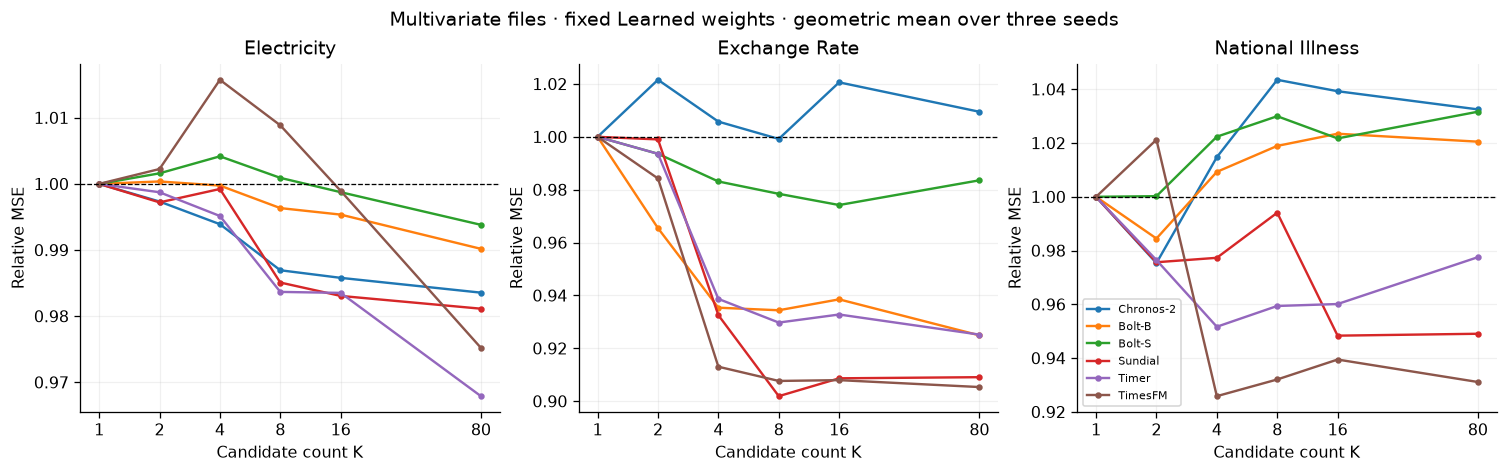

K                                              1       2       4       8   \
dataset          model                                                      
electricity      chronos-2                1.00000 0.99733 0.99391 0.98694   
                 chronos-bolt-base        1.00000 1.00037 0.99975 0.99634   
                 chronos-bolt-small       1.00000 1.00160 1.00417 1.00091   
                 sundial-base-128m        1.00000 0.99720 0.99923 0.98509   
                 timer-base-84m           1.00000 0.99874 0.99515 0.98367   
                 timesfm-2.0-500m-pytorch 1.00000 1.00225 1.01574 1.00886   
exchange_rate    chronos-2                1.00000 1.02157 1.00576 0.99920   
                 chronos-bolt-base        1.00000 0.96546 0.93537 0.93440   
                 chronos-bolt-small       1.00000 0.99359 0.98311 0.97845   
                 sundial-base-128m        1.00000 0.99902 0.93255 0.90191   
                 timer-base-84m           1.00000 0.99357 0.93870 0.92975   
                 timesfm-2.0-500m-pytorch 1.00000 0.98425 0.91304 0.90767   
national_illness chronos-2                1.00000 0.97534 1.01474 1.04352   
                 chronos-bolt-base        1.00000 0.98448 1.00927 1.01893   
                 chronos-bolt-small       1.00000 1.00024 1.02235 1.02997   
                 sundial-base-128m        1.00000 0.97566 0.97731 0.99408   
                 timer-base-84m           1.00000 0.97647 0.95166 0.95939   
                 timesfm-2.0-500m-pytorch 1.00000 1.02123 0.92585 0.93206   

K                                              16      80  
dataset          model                                     
electricity      chronos-2                0.98579 0.98356  
                 chronos-bolt-base        0.99536 0.99018  
                 chronos-bolt-small       0.99875 0.99381  
                 sundial-base-128m        0.98306 0.98113  
                 timer-base-84m           0.98352 0.96790  
                 timesfm-2.0-500m-pytorch 0.99895 0.97521  
exchange_rate    chronos-2                1.02061 1.00948  
                 chronos-bolt-base        0.93853 0.92492  
                 chronos-bolt-small       0.97420 0.98355  
                 sundial-base-128m        0.90866 0.90909  
                 timer-base-84m           0.93280 0.92519  
                 timesfm-2.0-500m-pytorch 0.90797 0.90536  
national_illness chronos-2                1.03927 1.03251  
                 chronos-bolt-base        1.02346 1.02051  
                 chronos-bolt-small       1.02172 1.03164  
                 sundial-base-128m        0.94835 0.94906  
                 timer-base-84m           0.96012 0.97753  
                 timesfm-2.0-500m-pytorch 0.93947 0.93112

Nonincreasing curves: 2 / 18


In [2]:
all_budget = load_snapshot('lw_budget')
assert len(all_budget) == 1944
budget = all_budget[(all_budget.split=='test') & (all_budget.rule=='weighted')]
display(lw_budget_summary())
def budget_plot(frame, title):
    datasets = list(frame.dataset.unique())
    fig, axes = plt.subplots(1, len(datasets), figsize=(13, 4), layout='constrained')
    for ax, dataset in zip(axes, datasets):
        for model, group in frame[frame.dataset==dataset].groupby('model'):
            curve = group.groupby('K').relative_mse.agg(geometric)
            ax.plot(curve.index, curve.values, 'o-', ms=3, label=MODEL_LABELS[model])
        ax.axhline(1, color='black', ls='--', lw=.8)
        ax.set_xscale('log', base=2); ax.set_xticks([1,2,4,8,16,80], ['1','2','4','8','16','80'])
        ax.set(title=dataset.replace('_',' ').title(), xlabel='Candidate count K', ylabel='Relative MSE')
    axes[-1].legend(fontsize=7); fig.suptitle(title, fontsize=12); plt.show()
budget_plot(budget, 'Multivariate files · fixed Learned weights · geometric mean over three seeds')
detail = summarize(budget, ['dataset','model','K'])
display(detail.pivot(index=['dataset','model'], columns='K', values='relative_mse'))
curves = detail.sort_values('K').groupby(['model','dataset'])
print('Nonincreasing curves:', sum(np.all(np.diff(g.relative_mse)<=1e-10) for _, g in curves), '/', len(curves))
